# Giai đoạn 3a: Tìm các "kiểu ngày" ô nhiễm bằng clustering

**Loại công việc: data mining** (học không giám sát, *unsupervised learning*). Không có nhãn đúng/sai; ta để thuật toán gom các ngày có đường cong PM2.5 giống nhau, rồi tự đặt tên và mô tả từng nhóm. Phần mô tả điều kiện đi kèm ở cuối là **data analysis** (thống kê mô tả) trên kết quả mining.

**Clustering** = chia các đối tượng (ở đây: mỗi ngày là một vectơ 24 giá trị PM2.5) thành các nhóm sao cho trong nhóm giống nhau, giữa các nhóm khác nhau.

Đầu vào: `../phase1/data/clean/hanoi_daily.parquet` (2.230 ngày: có đường cong 24h và ≥ 18 giờ đo thật) (đường cong `pm25_h00..h23`, thời tiết theo ngày, điểm cháy, Tết, giãn cách) và `hanoi_hourly_enriched.parquet` (để tính điều kiện trong ngày: gió sáng/tối, mưa sáng/tối).

Đầu ra:
- `data/day_clusters.csv` (+ `.parquet`): nhãn cụm cho từng ngày, dùng cho bước association rules.
- Hình `reports/11_*.png` … `reports/19_*.png`, bảng `reports/1*_*.csv`.

**Nhắc lại:** mọi so sánh điều kiện ở đây là **mối liên hệ**, không phải nhân quả. Dữ liệu từ **một trạm** (Đại sứ quán Mỹ, Ba Đình).

In [1]:
from pathlib import Path
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)

BASE = Path(os.environ.get("HANOI_AQ_DIR", ".."))
CLEAN = BASE / "phase1" / "data" / "clean"
REPORT = Path("reports"); REPORT.mkdir(exist_ok=True)
OUT = Path("data"); OUT.mkdir(exist_ok=True)
SEED = 0

h = pd.read_parquet(CLEAN / "hanoi_hourly_enriched.parquet")
d_all = pd.read_parquet(CLEAN / "hanoi_daily.parquet")

HCOLS = [f"pm25_h{i:02d}" for i in range(24)]
SEASON = {12: "Đông", 1: "Đông", 2: "Đông", 3: "Xuân", 4: "Xuân", 5: "Hè", 6: "Hè", 7: "Hè", 8: "Hè", 9: "Hè", 10: "Thu", 11: "Thu"}
S_ORDER = ["Đông", "Xuân", "Hè", "Thu"]
d_all["season"] = pd.Categorical(d_all["month"].map(SEASON), S_ORDER)

# Ngày có đủ 24 giờ (sau nội suy khoảng <= 3h ở Giai đoạn 1) VÀ là ngày đủ (>= 18 giờ đo thật).
# 35 ngày có đường cong đủ nhờ nội suy nhưng < 18 giờ đo thật -> loại, vì hình dạng của chúng phần lớn là đường nội suy.
cc = d_all["curve_complete"]
print("đường cong 24h:", int(cc.sum()), "| trong đó không đủ 18 giờ đo thật:", int((cc & ~d_all["day_ok"]).sum()))
c = d_all[cc & d_all["day_ok"]].copy()
print("ngày dùng để phân cụm:", len(c), "|", c.index.min().date(), "->", c.index.max().date())

đường cong 24h: 2265 | trong đó không đủ 18 giờ đo thật: 35
ngày dùng để phân cụm: 2230 | 2016-02-01 -> 2025-04-08


## 1. Kiểm tra chất lượng trước khi phân cụm

Clustering rất nhạy với dữ liệu bẩn: một giờ ngoại lai có thể kéo cả ngày sang cụm khác. Kiểm tra:
1. **Múi giờ**: đường cong `h00..h23` phải là giờ địa phương (Asia/Ho_Chi_Minh), nếu không "đỉnh tối" sẽ bị dịch.
2. **Giá trị 0 hoặc rất nhỏ**: log(0) không xác định, cần chặn dưới.
3. **Giờ gắn cờ spike/nội suy**: bao nhiêu ngày chứa chúng.
4. **Mẫu ngày lệch theo mùa/năm** (do các khoảng thiếu lớn): ảnh hưởng tới tỷ lệ cụm theo năm.

tz bảng giờ: Asia/Ho_Chi_Minh
giờ có PM2.5 < 1 µg/m³: 12 (0.02% số giờ) -> chặn dưới = 1 trước khi lấy log
ngày chứa >= 1 giờ gắn cờ spike: 170
ngày có giờ nội suy: 572 | trung bình 2.3 giờ/ngày có nội suy


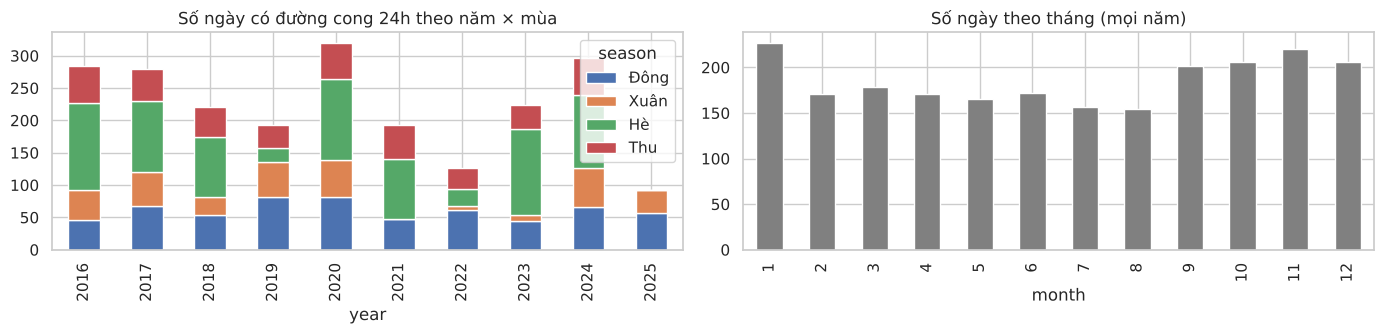

In [2]:
print("tz bảng giờ:", h.index.tz)
vals = c[HCOLS].values
print("giờ có PM2.5 < 1 µg/m³:", int((vals < 1).sum()), f"({(vals < 1).mean()*100:.2f}% số giờ) -> chặn dưới = 1 trước khi lấy log")
print("ngày chứa >= 1 giờ gắn cờ spike:", int((c["n_spike_h"] > 0).sum()))

hh = h.copy(); hh["d"] = hh["date"]
interp = hh.groupby("d")["flag_interpolated"].sum().reindex(c.index).fillna(0)
print("ngày có giờ nội suy:", int((interp > 0).sum()), "| trung bình", round(interp[interp > 0].mean(), 1), "giờ/ngày có nội suy")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
pd.crosstab(c["year"], c["season"]).plot(kind="bar", stacked=True, ax=ax[0]); ax[0].set_title("Số ngày có đường cong 24h theo năm × mùa")
c.groupby("month").size().plot(kind="bar", ax=ax[1], color="grey"); ax[1].set_title("Số ngày theo tháng (mọi năm)")
plt.tight_layout(); plt.savefig(REPORT / "11_sample.png"); plt.show()

**Đọc:** múi giờ đúng; số giờ < 1 µg/m³ rất ít nên chặn dưới bằng 1 không ảnh hưởng đáng kể. Mẫu ngày không đều giữa các năm (2022 và 2025 ít ngày, 2019/2021/2022 thiếu nhiều tháng hè hoặc xuân). Hệ quả: **không so sánh tỷ lệ cụm giữa các năm** như một xu hướng; chỉ so theo tháng/mùa.

## 2. Biểu diễn một ngày: tách **mức** (level) và **hình dạng** (shape)

Mỗi ngày là vectơ 24 giờ. Câu hỏi "kiểu ngày" có hai mặt:
- **Mức**: ngày bẩn hay sạch (trung bình ngày). EDA đã cho thấy mức chủ yếu đi theo mùa và gió.
- **Hình dạng**: PM2.5 lên xuống thế nào trong ngày (đỉnh tối, tăng dần, giảm dần, phẳng…).

Các lựa chọn:

| Cách | Đặc trưng đưa vào thuật toán | Ưu | Nhược |
|---|---|---|---|
| A. Log đường cong | log x (24 chiều) | một bước, đơn giản | **mức chiếm gần hết phương sai** → cụm gần như = mùa/mức, hình dạng bị lấn át |
| B. Tách 2 tầng (**chọn**) | cụm trên hình dạng `log x − mean(log x)`; mức chia thành bậc theo ngưỡng | hai câu hỏi tách bạch, dễ diễn giải, mức gắn với quy chuẩn | phải chọn ngưỡng mức; hai tầng độc lập |
| C. Gộp có trọng số | hình dạng + mức × trọng số w | một mô hình | kết quả phụ thuộc w, khó giải thích chọn w |

Dùng **log** vì PM2.5 lệch phải (Nhật ký quyết định 22/11). Trên thang log, `log x − mean(log x)` = log(x / trung bình hình học của ngày): giá trị 0 = bằng mức trung bình của ngày, +0,4 ≈ cao hơn 50%. Như vậy hai ngày có cùng "nhịp" nhưng một ngày gấp đôi ngày kia sẽ có cùng hình dạng.

Kiểm tra nhanh vì sao A không phù hợp: PCA trên log đường cong.

In [3]:
L = np.log(c[HCOLS].clip(lower=1))
level = L.mean(axis=1)                         # log trung bình hình học của ngày
S = L.sub(level, axis=0)                       # hình dạng
c["log_level"] = level
c["gmean"] = np.exp(level)                     # trung bình hình học (µg/m³)
c["shape_amp"] = S.std(axis=1)                 # biên độ dao động trong ngày (độ lệch chuẩn của hình dạng)

pA = PCA(5).fit(L.values)
print("A. PCA trên log đường cong, % phương sai:", (pA.explained_variance_ratio_ * 100).round(1))
pc1 = pA.transform(L.values)[:, 0]
print("tương quan PC1 với mức log trung bình ngày: r =", round(np.corrcoef(pc1, level)[0, 1], 3))
pB = PCA(6).fit(S.values)
print("B. PCA trên hình dạng, % phương sai:", (pB.explained_variance_ratio_ * 100).round(1))

A. PCA trên log đường cong, % phương sai: [70.2  9.1  7.2  3.1  2.1]
tương quan PC1 với mức log trung bình ngày: r = 1.0
B. PCA trên hình dạng, % phương sai: [31.2 23.8 10.4  7.   5.   3.4]


**Đọc:** với cách A, thành phần thứ nhất gần như chính là **mức** trung bình ngày và chiếm phần lớn phương sai; mọi thuật toán dựa trên khoảng cách Euclid sẽ chủ yếu chia theo mức. Với cách B, phương sai trải đều hơn trên nhiều thành phần: hình dạng là một cấu trúc liên tục, nhiều chiều, nên các cụm sẽ không tách bạch (silhouette thấp là điều dự kiến, xem EDA phần 10).

**Quyết định:** dùng **cách B**: clustering trên hình dạng; mức để thành **bậc** cố định:
- `thấp`: trung bình ngày ≤ 25 µg/m³
- `TB`: 25–50 µg/m³
- `cao`: > 50 µg/m³ (vượt QCVN 05:2023 trung bình 24h)

Lấy `pm25_mean` (trung bình số học) để so với quy chuẩn, vì quy chuẩn định nghĩa theo trung bình số học. Mốc 25 là lựa chọn của dự án (một nửa ngưỡng QCVN), không phải ngưỡng pháp lý; WHO 15 không dùng làm mốc vì 96% số ngày đã vượt. Lựa chọn khác: chia theo tam phân vị (tertile), hoặc theo bậc AQI của US EPA.

In [4]:
c["level_tier"] = pd.cut(c["pm25_mean"], [0, 25, 50, np.inf], labels=["thấp", "TB", "cao"])
print(c["level_tier"].value_counts().reindex(["thấp", "TB", "cao"]))
display(pd.crosstab(c["season"], c["level_tier"], normalize="index").round(2))

level_tier
thấp     510
TB      1020
cao      700
Name: count, dtype: int64


level_tier,thấp,TB,cao
season,,,
Đông,0.10,0.36,0.54
Xuân,0.10,0.58,0.32
Hè,0.41,0.50,0.09
Thu,0.15,0.41,0.44


## 3. Chọn thuật toán

| Thuật toán | Ý tưởng | Khi nào hợp |
|---|---|---|
| **k-means** (Euclid) — *chọn làm chính* | gán mỗi điểm vào tâm gần nhất, cập nhật tâm, lặp | nhanh, tâm cụm = "đường cong đại diện" dễ vẽ; giả định cụm tròn, cỡ tương đương |
| Hierarchical (Ward) | gộp dần các nhóm sao cho tăng phương sai trong nhóm ít nhất | có dendrogram, thấy cấu trúc lồng nhau; O(n²) bộ nhớ, vẫn ổn với 2.277 ngày |
| Gaussian Mixture (GMM) | mỗi cụm là một phân phối chuẩn; gán mềm (xác suất) | có BIC để chọn k; nhiều tham số, nhạy khởi tạo |
| k-means + DTW | khoảng cách Dynamic Time Warping cho phép đỉnh lệch 1–2 giờ | nếu cùng "kiểu" nhưng đỉnh dao động giờ; chậm hơn, tâm cụm khó diễn giải |
| k-medoids, DBSCAN | tâm là ngày thật / cụm theo mật độ | bền với ngoại lai / tìm ngày bất thường (để cho bước anomaly detection) |

Chọn **k-means làm mô hình chính** vì: hình dạng đã chuẩn hóa nằm trên cùng thang, khoảng cách Euclid trên log tương ứng với chênh lệch tỷ lệ; tâm cụm dễ vẽ thành "đường cong điển hình". Các thuật toán khác dùng để **kiểm tra chéo** (mục 5): nếu các thuật toán khác nhau cho cụm gần giống, ta tin cụm hơn.

## 4. Chọn số cụm k

Không có k "đúng". Dùng nhiều tiêu chí cùng lúc:
- **Elbow** (khuỷu tay): tổng bình phương khoảng cách trong cụm (inertia) giảm chậm lại ở đâu.
- **Silhouette** (−1..1): mỗi ngày gần cụm của mình hơn cụm khác bao nhiêu.
- **BIC của GMM**: thấp hơn là tốt hơn, có phạt số tham số.
- **Độ ổn định bootstrap**: lấy mẫu lại có hoàn lại 30 lần, phân cụm lại, đo độ trùng với lời giải gốc bằng **ARI** (Adjusted Rand Index: 1 = trùng hoàn toàn, 0 = như ngẫu nhiên). Cụm thật sự có cấu trúc thì lặp lại được.
- **Khả năng diễn giải**: tâm cụm có đặt tên được không.

,inertia,silhouette,BIC_GMM,ARI_bootstrap_TB,ARI_bootstrap_p10,cụm_nhỏ_nhất
k,,,,,,
2,6366.110,0.167,38411.583,0.866,0.769,1094
3,5586.824,0.153,32451.233,0.866,0.754,635
4,5149.414,0.139,28252.348,0.813,0.703,417
5,4902.991,0.131,25568.285,0.587,0.378,286
6,4685.287,0.105,23748.216,0.725,0.507,280
7,4522.689,0.093,22479.283,0.616,0.411,259
8,4392.059,0.086,21452.721,0.493,0.398,176


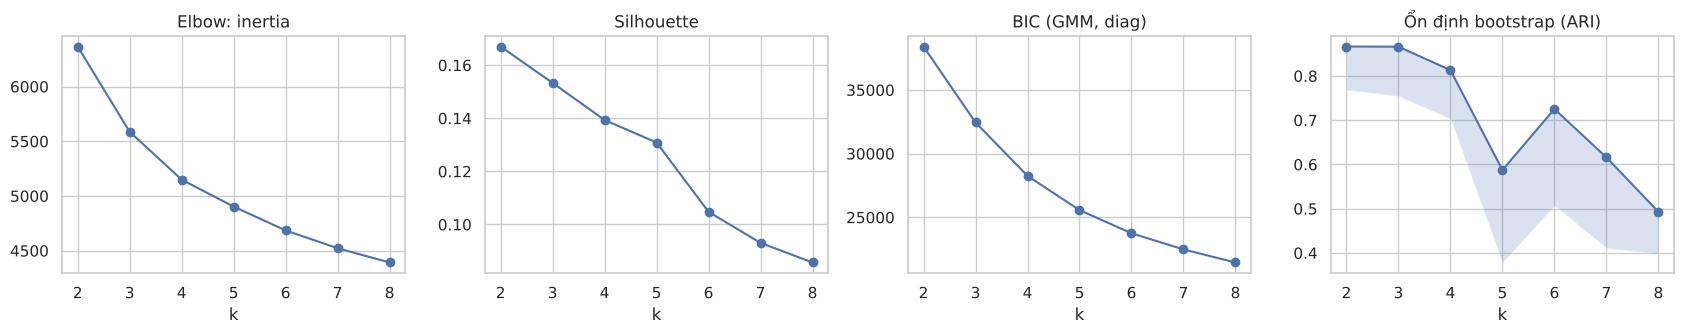

In [5]:
X = S.values
rng = np.random.default_rng(SEED)
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=20, random_state=SEED).fit(X)
    sil = silhouette_score(X, km.labels_)
    bic = GaussianMixture(k, covariance_type="diag", n_init=3, random_state=SEED).fit(X).bic(X)
    aris = []
    for b in range(30):
        idx = rng.choice(len(X), len(X), replace=True)
        kb = KMeans(k, n_init=10, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(km.labels_, kb.predict(X)))
    rows.append([k, km.inertia_, sil, bic, np.mean(aris), np.percentile(aris, 10), np.bincount(km.labels_).min()])
ksel = pd.DataFrame(rows, columns=["k", "inertia", "silhouette", "BIC_GMM", "ARI_bootstrap_TB", "ARI_bootstrap_p10", "cụm_nhỏ_nhất"]).set_index("k")
ksel.round(3).to_csv(REPORT / "12_choose_k.csv")
display(ksel.round(3))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.5))
ksel["inertia"].plot(marker="o", ax=ax[0], title="Elbow: inertia")
ksel["silhouette"].plot(marker="o", ax=ax[1], title="Silhouette")
ksel["BIC_GMM"].plot(marker="o", ax=ax[2], title="BIC (GMM, diag)")
ksel["ARI_bootstrap_TB"].plot(marker="o", ax=ax[3], title="Ổn định bootstrap (ARI)")
ax[3].fill_between(ksel.index, ksel["ARI_bootstrap_p10"], ksel["ARI_bootstrap_TB"], alpha=.2)
plt.tight_layout(); plt.savefig(REPORT / "12_choose_k.png"); plt.show()

**Đọc:**
- Inertia giảm đều, **không có khuỷu rõ**; silhouette thấp (khoảng 0,1–0,17) và giảm dần theo k; BIC giảm mãi (GMM luôn muốn thêm cụm trên dữ liệu liên tục). Ba tiêu chí này nói cùng một điều: **hình dạng ngày là một dải liên tục**, không có các nhóm tách rời tự nhiên. Đây là phát hiện, không phải lỗi.
- Vì vậy tiêu chí quyết định là **độ ổn định** và **diễn giải**. k = 2–4 lặp lại tốt khi lấy mẫu lại (ARI trung bình > 0,8); từ k = 5 độ ổn định rơi rõ (ARI ~0,5–0,7, dao động theo lần chạy): các cụm thêm vào chỉ là cách cắt tùy ý dải liên tục.
- k = 2 và 3 quá thô (chỉ "tăng về tối" vs "giảm về tối"). **Chọn k = 4**: ổn định nhất trong các k ≥ 4 và cả 4 tâm đều đặt tên được (mục 6).

## 5. Kiểm tra chéo với thuật toán khác (k = 4)

Nếu Ward, GMM và k-means-DTW cho cụm tương tự k-means thì cụm là đặc điểm của dữ liệu, không phải của thuật toán. Đo bằng ARI giữa từng cặp, và ARI giữa các lần chạy k-means với seed khác nhau.

In [6]:
K = 4
km = KMeans(K, n_init=50, random_state=SEED).fit(X)
lab_km = km.labels_
lab_ward = AgglomerativeClustering(K, linkage="ward").fit_predict(X)
lab_gmm = GaussianMixture(K, covariance_type="diag", n_init=5, random_state=SEED).fit(X).predict(X)

algos = {"k-means": lab_km, "Ward": lab_ward, "GMM": lab_gmm}
try:
    from tslearn.clustering import TimeSeriesKMeans
    dtw = TimeSeriesKMeans(K, metric="dtw", metric_params={"global_constraint": "sakoe_chiba", "sakoe_chiba_radius": 2},
                           n_init=2, max_iter=30, random_state=SEED).fit(X[:, :, None])
    algos["k-means DTW (±2h)"] = dtw.labels_
except ImportError:
    print("Chưa cài tslearn (pip install tslearn): bỏ qua DTW.")

names = list(algos)
ari_m = pd.DataFrame([[adjusted_rand_score(algos[a], algos[b]) for b in names] for a in names], index=names, columns=names)
display(ari_m.round(2))
seeds = [KMeans(K, n_init=1, random_state=s).fit(X).labels_ for s in range(10)]
print("k-means 10 seed (n_init=1), ARI trung bình với lời giải chính:", round(np.mean([adjusted_rand_score(lab_km, s) for s in seeds]), 3))

/usr/local/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


,k-means,Ward,GMM,k-means DTW (±2h)
k-means,1.00,0.37,0.47,0.27
Ward,0.37,1.00,0.30,0.28
GMM,0.47,0.30,1.00,0.24
k-means DTW (±2h),0.27,0.28,0.24,1.00


k-means 10 seed (n_init=1), ARI trung bình với lời giải chính: 0.897


**Đọc (chạy 22/11/2026):** k-means **ổn định với chính nó** (10 seed: ARI 0,90; bootstrap: 0,81), nhưng các thuật toán khác chỉ trùng **một phần**: GMM 0,47, Ward 0,37, DTW 0,27. Nghĩa là:
- Với cùng thuật toán, cách chia lặp lại được; nhưng thuật toán khác (giả định khác về hình dạng cụm) cắt dải liên tục ở chỗ khác. Không có "4 loại ngày tự nhiên" mà mọi thuật toán đều tìm ra.
- DTW khác nhiều nhất vì nó **bỏ qua lệch giờ ±2h**, mà với ta thời điểm (sáng hay tối) lại chính là thông tin cần giữ. Vì vậy Euclid phù hợp hơn cho câu hỏi này.

Hệ quả cho diễn giải: đọc mỗi cụm như một **kiểu điển hình** (prototype), không phải loại ngày tách biệt; ngày gần ranh giới có thể thuộc cụm bên cạnh. Ta lưu cột `shape_conf` (= 1 − khoảng cách tới tâm gần nhất / tâm gần thứ hai; 0 = ở ranh giới) để bước association rules có thể chạy lại chỉ trên ngày điển hình, ví dụ `shape_conf > 0,2`.

## 6. Mô hình cuối: k-means, k = 4, đặt tên các cụm

Đặt tên theo hình dạng tâm cụm (tỷ lệ so với trung bình hình học của ngày, `exp(tâm)`). Việc gán tên làm bằng quy tắc trên tâm cụm để chạy lại vẫn ra cùng tên:
- cụm có (tối − sáng) lớn nhất → **"Tăng dần về tối"**
- cụm có (tối − sáng) nhỏ nhất → **"Giảm dần trong ngày"**
- trong hai cụm còn lại, cụm có chiều thấp hơn đêm/tối nhiều nhất → **"Chữ U: cao đêm, thấp chiều"**; cụm kia → **"Phẳng, bướu ban ngày"**

In [7]:
cen = pd.DataFrame(km.cluster_centers_, columns=range(24))
night, morning, aft, eve = cen[list(range(0, 6))].mean(axis=1), cen[list(range(6, 12))].mean(axis=1), cen[list(range(12, 18))].mean(axis=1), cen[list(range(18, 24))].mean(axis=1)
slope = eve - morning
rise, fall = int(slope.idxmax()), int(slope.idxmin())
rest = [i for i in range(K) if i not in (rise, fall)]
dip = (aft - (night + eve) / 2)[rest]
u_shape = int(dip.idxmin()); flat = [i for i in rest if i != u_shape][0]
NAME = {u_shape: "U: cao đêm, thấp chiều", rise: "Tăng dần về tối", fall: "Giảm dần trong ngày", flat: "Phẳng, bướu ban ngày"}
ORDER = [NAME[u_shape], NAME[rise], NAME[fall], NAME[flat]]
CODE = {NAME[u_shape]: "S1_U", NAME[rise]: "S2_tang", NAME[fall]: "S3_giam", NAME[flat]: "S4_phang"}
c["shape_cluster"] = pd.Categorical([NAME[i] for i in lab_km], ORDER)
c["shape_code"] = c["shape_cluster"].map(CODE)

# độ chắc chắn: 1 - d1/d2 (0 = nằm đúng ranh giới, gần 1 = rất gần tâm của mình)
dist = km.transform(X); ds = np.sort(dist, axis=1)
c["shape_conf"] = 1 - ds[:, 0] / ds[:, 1]

cen.index = [NAME[i] for i in cen.index]
display(np.exp(cen.loc[ORDER, list(range(0, 24, 2))]).round(2))
print(c["shape_cluster"].value_counts().reindex(ORDER))

,0,2,4,6,8,10,12,14,16,18,20,22
"U: cao đêm, thấp chiều",1.26,1.25,1.22,1.14,0.99,0.79,0.69,0.64,0.75,1.08,1.29,1.30
Tăng dần về tối,0.80,0.69,0.65,0.73,0.85,0.94,0.95,0.96,1.12,1.52,1.71,1.58
Giảm dần trong ngày,1.15,1.27,1.39,1.44,1.39,1.19,1.03,0.81,0.77,0.80,0.73,0.65
"Phẳng, bướu ban ngày",0.84,0.82,0.86,0.98,1.11,1.17,1.17,1.05,1.05,1.12,1.03,0.88


shape_cluster
U: cao đêm, thấp chiều    535
Tăng dần về tối           414
Giảm dần trong ngày       421
Phẳng, bướu ban ngày      860
Name: count, dtype: int64


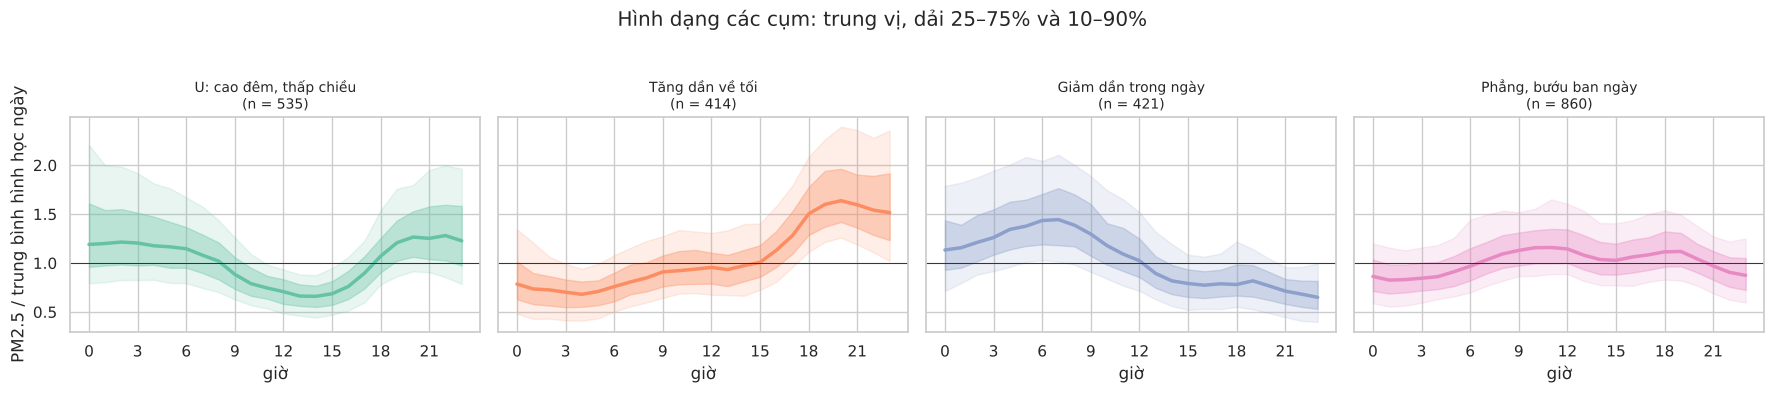

In [8]:
pal = dict(zip(ORDER, sns.color_palette("Set2", K)))
fig, ax = plt.subplots(1, K, figsize=(18, 3.8), sharey=True)
for a, n in zip(ax, ORDER):
    R = np.exp(S[c["shape_cluster"] == n])
    q = R.quantile([.1, .25, .5, .75, .9])
    a.fill_between(range(24), q.loc[.1], q.loc[.9], color=pal[n], alpha=.15)
    a.fill_between(range(24), q.loc[.25], q.loc[.75], color=pal[n], alpha=.35)
    a.plot(range(24), q.loc[.5], color=pal[n], lw=2.5)
    a.axhline(1, c="k", lw=.6); a.set_xticks(range(0, 24, 3))
    a.set_title(f"{n}\n(n = {len(R)})", fontsize=10); a.set_xlabel("giờ")
ax[0].set_ylabel("PM2.5 / trung bình hình học ngày")
plt.suptitle("Hình dạng các cụm: trung vị, dải 25–75% và 10–90%", y=1.03)
plt.tight_layout(); plt.savefig(REPORT / "13_shape_clusters.png", bbox_inches="tight"); plt.show()

**Cách đọc:** trục tung là tỷ lệ so với mức trung bình (hình học) của chính ngày đó, nên 1,5 = cao hơn 50% so với mức chung của ngày. Dải màu rộng cho thấy trong mỗi cụm vẫn có biến thiên đáng kể (dải liên tục, xem mục 4).

**Bốn hình dạng:**
- **U: cao đêm, thấp chiều** (535 ngày): cao suốt đêm đến sáng (~1,25×), thấp nhất 13–15h (~0,65×), lên lại sau 18h. Đây là nhịp "kinh điển" gắn với lớp biên: đêm lớp biên thấp, chiều lớp biên cao nhất.
- **Tăng dần về tối** (414): sáng sớm thấp (~0,65×), tăng dần, đỉnh 20h (~1,7×). Ô nhiễm **tích tụ trong ngày**.
- **Giảm dần trong ngày** (421): cao từ đêm đến 6–8h (~1,45×), giảm dần, cuối ngày thấp (~0,65×). Ô nhiễm **tan dần**.
- **Phẳng, bướu ban ngày** (860, nhóm lớn nhất): dao động nhỏ (0,8–1,2×), hơi cao 8–12h. Gần với "ngày trung bình", cụm này hút các ngày không có nhịp rõ.

## 7. Ghép mức và hình dạng: "kiểu ngày" = hình dạng × bậc mức

Hình dạng và mức có độc lập không? Nếu một hình dạng gần như luôn đi với mức cao thì hai tầng đang nói cùng một chuyện.

level_tier,thấp,TB,cao,Tổng
shape_cluster,,,,
"U: cao đêm, thấp chiều",115,191,229,535
Tăng dần về tối,126,200,88,414
Giảm dần trong ngày,60,177,184,421
"Phẳng, bướu ban ngày",209,452,199,860
Tổng,510,1020,700,2230


level_tier,thấp,TB,cao
shape_cluster,,,
"U: cao đêm, thấp chiều",0.21,0.36,0.43
Tăng dần về tối,0.30,0.48,0.21
Giảm dần trong ngày,0.14,0.42,0.44
"Phẳng, bướu ban ngày",0.24,0.53,0.23


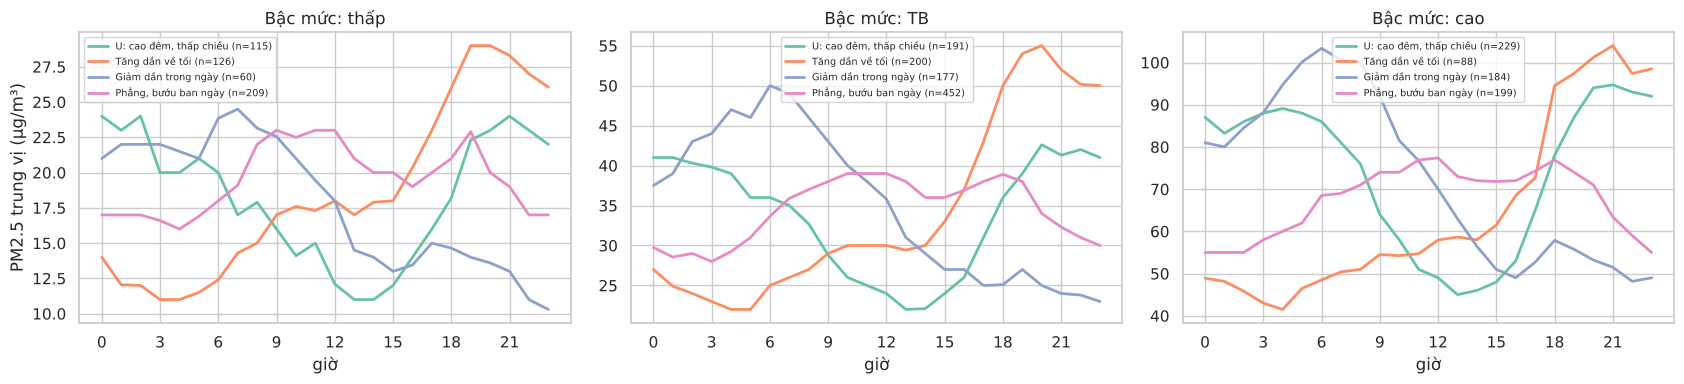

In [9]:
ct = pd.crosstab(c["shape_cluster"], c["level_tier"], margins=True, margins_name="Tổng")
display(ct)
display(pd.crosstab(c["shape_cluster"], c["level_tier"], normalize="index").round(2))

# Đường cong thực (µg/m³) trung vị theo hình dạng × bậc mức
fig, ax = plt.subplots(1, 3, figsize=(17, 4), sharey=False)
for a, t in zip(ax, ["thấp", "TB", "cao"]):
    for n in ORDER:
        m = (c["shape_cluster"] == n) & (c["level_tier"] == t)
        if m.sum() >= 15:
            a.plot(range(24), c.loc[m, HCOLS].median().values, color=pal[n], lw=2, label=f"{n} (n={m.sum()})")
    a.set_title(f"Bậc mức: {t}"); a.set_xticks(range(0, 24, 3)); a.set_xlabel("giờ"); a.legend(fontsize=7)
ax[0].set_ylabel("PM2.5 trung vị (µg/m³)")
plt.tight_layout(); plt.savefig(REPORT / "14_shape_by_level.png"); plt.show()
c["day_type"] = c["shape_code"].astype(str) + "|" + c["level_tier"].astype(str)

**Đọc:** mỗi hình dạng xuất hiện ở cả ba bậc mức, nên hai tầng bổ sung cho nhau chứ không trùng lặp. Tuy vậy có xu hướng: "U" và "Giảm dần" nghiêng về bậc **cao** (42–43% số ngày > 50 µg/m³), "Tăng dần" nghiêng về bậc thấp/TB (chỉ 21% cao). Biến `day_type` (ví dụ `S2_tang|cao`) là nhãn kết hợp để bước association rules dùng.

## 8. Các kiểu ngày xuất hiện khi nào? (tháng, mùa)

Tỷ lệ mỗi cụm theo tháng (cộng dồn = 100% trong mỗi tháng). Vì mẫu ngày lệch giữa các năm (mục 1), không vẽ theo năm.

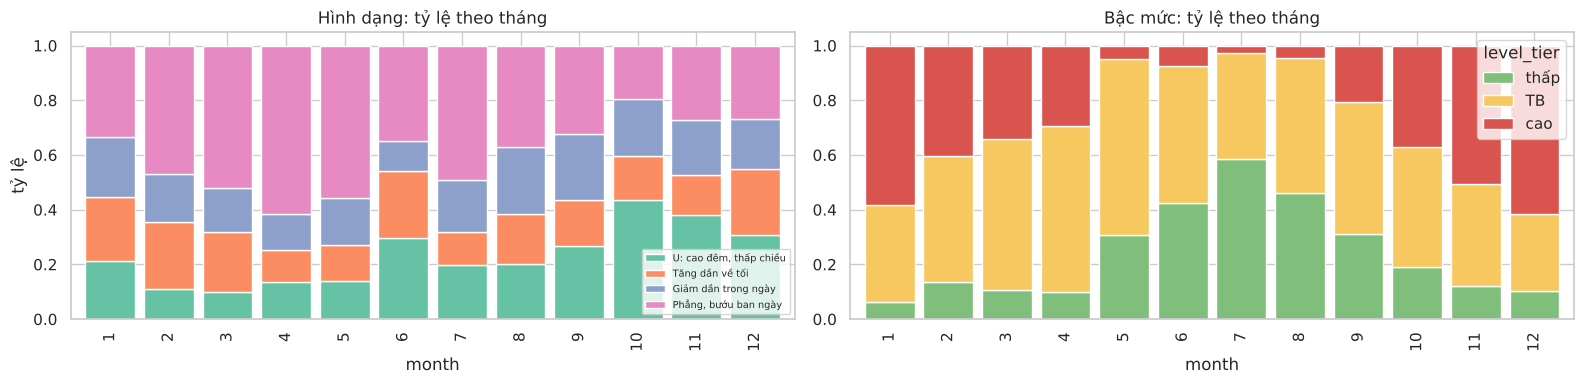

season,Đông,Xuân,Hè,Thu
shape_cluster,,,,
"U: cao đêm, thấp chiều",0.22,0.12,0.22,0.41
Tăng dần về tối,0.24,0.17,0.17,0.15
Giảm dần trong ngày,0.20,0.15,0.19,0.20
"Phẳng, bướu ban ngày",0.35,0.57,0.41,0.23


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
pm = pd.crosstab(c["month"], c["shape_cluster"], normalize="index")[ORDER]
pm.plot(kind="bar", stacked=True, color=[pal[n] for n in ORDER], ax=ax[0], width=.85)
ax[0].set_title("Hình dạng: tỷ lệ theo tháng"); ax[0].legend(fontsize=7, loc="lower right"); ax[0].set_ylabel("tỷ lệ")
pl = pd.crosstab(c["month"], c["level_tier"], normalize="index")
pl.plot(kind="bar", stacked=True, color=["#7fbf7b", "#f6c85f", "#d9534f"], ax=ax[1], width=.85)
ax[1].set_title("Bậc mức: tỷ lệ theo tháng")
plt.tight_layout(); plt.savefig(REPORT / "15_by_month.png"); plt.show()
display(pd.crosstab(c["shape_cluster"], c["season"], normalize="columns").round(2))

**Đọc:** "U" chiếm 40% số ngày mùa Thu (tháng 10–11), ít ở mùa Xuân (13%). "Phẳng" chiếm 57% mùa Xuân (tháng 3–4, nồm ẩm, ít nắng nên lớp biên dao động ít). "Tăng dần" và "Giảm dần" có mặt quanh năm (15–24% mỗi mùa): đây là các ngày chuyển tiếp, không gắn với mùa nào.

## 9. Điều kiện đi kèm mỗi kiểu ngày (data analysis trên kết quả mining)

Vì mùa là biến gây nhiễu mạnh (Nhật ký quyết định 22/11), so sánh theo hai cách:
1. **Giá trị thô** (trung vị) của từng cụm, để có con số dễ hình dung.
2. **Độ lệch so với khí hậu tháng** (*anomaly*): giá trị ngày trừ trung vị của cùng tháng (mọi năm). Anomaly dương = cao hơn bình thường của tháng đó. Cách này loại phần lớn ảnh hưởng của mùa: một cụm có anomaly gió âm nghĩa là gió yếu hơn bình thường **so với cùng thời điểm trong năm**.

Thêm các biến **trong ngày** từ bảng giờ, vì hình dạng là chuyện diễn biến trong ngày:
- gió buổi tối (18–23h) trừ gió buổi sáng (6–11h); lớp biên (BLH) đêm (0–5h); mưa buổi sáng vs chiều tối
- mức PM2.5 hôm trước và hôm sau (log tỷ số), để xem cụm có phải là "đầu đợt" hay "cuối đợt" ô nhiễm.

In [11]:
hh = h.copy()
hh["d"] = hh["date"]
seg = lambda a, b: hh[(hh["hour"] >= a) & (hh["hour"] < b)].groupby("d")
intra = pd.DataFrame({
    "ws_am": seg(6, 12)["wind_speed_10m"].mean(),
    "ws_eve": seg(18, 24)["wind_speed_10m"].mean(),
    "blh_night": seg(0, 6)["boundary_layer_height"].mean(),
    "blh_aft": seg(12, 18)["boundary_layer_height"].mean(),
    "rain_0_12": seg(0, 12)["precipitation"].sum(),
    "rain_12_24": seg(12, 24)["precipitation"].sum(),
})
intra["ws_eve_minus_am"] = intra["ws_eve"] - intra["ws_am"]
intra.index = pd.DatetimeIndex(intra.index)
c = c.join(intra[["ws_eve_minus_am", "blh_night", "blh_aft", "rain_0_12", "rain_12_24"]])

# mức hôm trước / hôm sau (chỉ khi ngày đó đủ dữ liệu)
lv = np.log(d_all["pm25_mean"].where(d_all["day_ok"]))
lv = lv.reindex(pd.date_range(lv.index.min(), lv.index.max(), freq="D"))
c["dlog_prev"] = np.log(c["pm25_mean"]) - lv.shift(1).reindex(c.index).values   # hôm nay so với hôm qua
c["dlog_next"] = lv.shift(-1).reindex(c.index).values - np.log(c["pm25_mean"])   # ngày mai so với hôm nay
c["rain_any"] = c["precip_sum"] >= 1
c["fire_rrd"] = c["viirs_n_rrd"]

VARS = {"pm25_mean": "PM2.5 TB ngày", "ws_mean": "gió TB (m/s)", "ws_eve_minus_am": "gió tối − sáng", "precip_sum": "mưa (mm)",
        "rain_0_12": "mưa 0–12h", "rain_12_24": "mưa 12–24h", "blh_mean": "BLH TB (m)", "blh_night": "BLH đêm",
        "t_range": "biên độ nhiệt (°C)", "rh_mean": "độ ẩm (%)", "fire_rrd": "điểm cháy ĐBSH",
        "dlog_prev": "log(hôm nay/hôm qua)", "dlog_next": "log(mai/hôm nay)"}
raw = c.groupby("shape_cluster", observed=True)[list(VARS)].median().rename(columns=VARS)
raw.insert(0, "số ngày", c["shape_cluster"].value_counts())
raw["% ngày mưa ≥1mm"] = c.groupby("shape_cluster", observed=True)["rain_any"].mean() * 100
raw["% ngày Tết"] = c.groupby("shape_cluster", observed=True)["is_tet_holiday"].mean() * 100
raw["% ngày giãn cách"] = c.groupby("shape_cluster", observed=True)["lockdown"].mean() * 100
raw.round(2).to_csv(REPORT / "16_conditions_raw.csv")
display(raw.round(2))

,số ngày,PM2.5 TB ngày,gió TB (m/s),gió tối − sáng,mưa (mm),mưa 0–12h,mưa 12–24h,BLH TB (m),BLH đêm,biên độ nhiệt (°C),độ ẩm (%),điểm cháy ĐBSH,log(hôm nay/hôm qua),log(mai/hôm nay),% ngày mưa ≥1mm,% ngày Tết,% ngày giãn cách
shape_cluster,,,,,,,,,,,,,,,,,
"U: cao đêm, thấp chiều",535,42.79,2.33,-0.61,0.0,0.0,0.0,415.31,107.50,7.0,75.12,2.0,0.04,0.08,35.14,0.93,3.36
Tăng dần về tối,414,33.00,2.39,-0.72,0.7,0.4,0.0,405.73,238.75,5.7,80.02,0.0,0.09,0.28,46.38,2.66,1.69
Giảm dần trong ngày,421,44.62,2.25,0.42,1.0,0.3,0.4,382.92,87.08,6.8,83.54,1.0,-0.05,-0.24,50.83,2.14,3.80
"Phẳng, bướu ban ngày",860,35.26,2.44,0.34,1.0,0.3,0.3,412.40,167.50,6.7,83.38,1.0,-0.01,-0.02,50.70,3.14,2.67


,gió TB (m/s),gió tối − sáng,mưa (mm),mưa 0–12h,mưa 12–24h,BLH TB (m),BLH đêm,biên độ nhiệt (°C),độ ẩm (%),điểm cháy ĐBSH,log PM2.5
shape_cluster,,,,,,,,,,,
"U: cao đêm, thấp chiều",0.00,-0.33,0.0,0.0,0.0,10.57,-21.67,0.5,-4.48,1.0,0.14
Tăng dần về tối,0.03,-0.58,0.2,0.2,0.0,5.52,88.33,-0.9,-0.77,0.0,-0.17
Giảm dần trong ngày,-0.11,0.56,0.1,0.0,0.1,-13.02,-45.62,0.2,1.52,0.0,0.18
"Phẳng, bướu ban ngày",0.03,0.29,0.1,0.0,0.1,0.57,5.83,0.1,1.27,0.0,-0.06


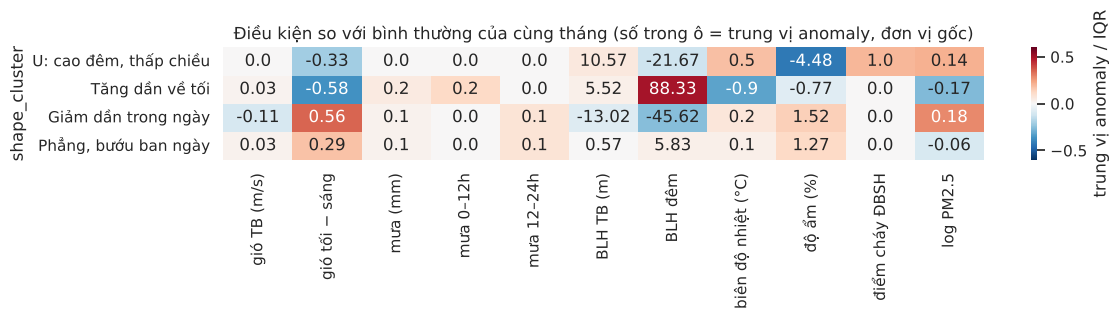

In [12]:
ANOM = ["ws_mean", "ws_eve_minus_am", "precip_sum", "rain_0_12", "rain_12_24", "blh_mean", "blh_night", "t_range", "rh_mean", "fire_rrd"]
an = c[ANOM] - c.groupby("month")[ANOM].transform("median")
an["log_pm"] = np.log(c["pm25_mean"]) - np.log(c["pm25_mean"]).groupby(c["month"]).transform("median")
an["shape_cluster"] = c["shape_cluster"]
an_tab = an.groupby("shape_cluster", observed=True).median().rename(columns={**VARS, "log_pm": "log PM2.5"})
an_tab.round(2).to_csv(REPORT / "17_conditions_anomaly.csv")
display(an_tab.round(2))

# chuẩn hóa để vẽ heatmap: chia cho độ lệch tứ phân vị (IQR) của anomaly
z = an_tab / (an.drop(columns="shape_cluster").quantile(.75) - an.drop(columns="shape_cluster").quantile(.25)).rename({**VARS, "log_pm": "log PM2.5"}).replace(0, np.nan)
plt.figure(figsize=(12, 3.2))
sns.heatmap(z, center=0, cmap="RdBu_r", annot=an_tab.round(2), fmt="", vmin=-.6, vmax=.6, cbar_kws={"label": "trung vị anomaly / IQR"})
plt.title("Điều kiện so với bình thường của cùng tháng (số trong ô = trung vị anomaly, đơn vị gốc)")
plt.tight_layout(); plt.savefig(REPORT / "17_conditions_anomaly.png"); plt.show()

**Cách đọc heatmap:** màu đỏ = cao hơn bình thường của tháng, xanh = thấp hơn. Ví dụ ô "gió tối − sáng" âm ở một cụm nghĩa là trong các ngày thuộc cụm đó, gió buổi tối yếu đi so với buổi sáng nhiều hơn mức thường gặp trong tháng.

Các biến có anomaly trung vị bằng 0 (mưa, điểm cháy) là do phần lớn ngày không mưa/không có điểm cháy; xem thêm cột "% ngày mưa" ở bảng thô.

**Đọc (mối liên hệ, không phải nhân quả):**
- **U: cao đêm, thấp chiều**: ngày **khô** (35% có mưa ≥ 1 mm, so với ~50% ở các cụm khác), độ ẩm thấp hơn bình thường của tháng ~5 điểm %, biên độ nhiệt lớn hơn, lớp biên ban đêm thấp hơn bình thường. Khớp với hình ảnh đêm trời quang, nguội nhanh, nghịch nhiệt gần mặt đất giữ bụi; chiều nắng làm lớp biên dâng lên và pha loãng. Mức PM2.5 cao hơn bình thường của tháng ~12% (exp 0,11).
- **Tăng dần về tối**: gió buổi tối **yếu đi** so với buổi sáng nhiều hơn bình thường (−0,6 m/s so với trung vị tháng), lớp biên đêm cao hơn bình thường; mức hôm nay thấp hơn bình thường của tháng ~17%, nhưng **ngày mai cao hơn hôm nay ~32%** (trung vị log = 0,28). Đây có dáng **ngày mở đầu một đợt ô nhiễm**: sáng còn sạch (sau mưa/gió), chiều tối gió lặng và bụi tích tụ.
- **Giảm dần trong ngày**: ngược lại, gió buổi tối **mạnh lên** (+0,5 m/s so với bình thường), lớp biên thấp hơn, ẩm hơn, mức hôm nay cao hơn bình thường ~19% nhưng **ngày mai thấp hơn ~21%**. Dáng **ngày kết thúc một đợt**: sáng còn tồn bụi từ đêm, rồi gió (thường là gió mùa/front lạnh hoặc mưa) quét sạch dần.
- **Phẳng, bướu ban ngày**: điều kiện gần bình thường ở mọi biến; mức hôm nay ≈ hôm qua ≈ ngày mai. Ngày "ổn định", nhịp trong ngày yếu (thường ẩm, nhiều mây).
- **Điểm cháy**: chỉ "U" có trung vị điểm cháy cao hơn bình thường một chút (+1 điểm); với các cụm khác không khác biệt. Điểm cháy liên hệ với **mức** (mục 9b) rõ hơn là với hình dạng.

### 9b. Điều kiện theo **bậc mức** trong từng mùa

EDA cho thấy mức PM2.5 liên hệ mạnh nhất với gió và lớp biên **trong cùng mùa**. Kiểm tra lại với bậc mức (chỉ mô tả, không phải nhân quả).

In [13]:
LV = ["ws_mean", "blh_mean", "precip_sum", "t_range", "rh_mean", "fire_rrd"]
tl = c.groupby(["season", "level_tier"], observed=True)[LV].median().rename(columns=VARS)
tl.insert(0, "số ngày", c.groupby(["season", "level_tier"], observed=True).size())
tl.round(2).to_csv(REPORT / "18_conditions_by_level_season.csv")
display(tl.round(2))

số ngày  gió TB (m/s)  BLH TB (m)  mưa (mm)  biên độ nhiệt (°C)  độ ẩm (%)  điểm cháy ĐBSH
season level_tier                                                                                            
Đông   thấp             58          3.55      540.42      1.45                3.80      79.12             0.0
       TB              218          3.07      459.27      0.70                6.10      81.98             0.0
       cao             328          2.01      357.19      0.00                7.70      74.52             3.0
Xuân   thấp             36          3.29      535.21      1.75                5.25      83.67             0.0
       TB              203          2.99      452.71      0.60                6.70      83.79             0.0
       cao             111          2.17      406.67      0.00                8.20      81.17             1.0
Hè     thấp            350          2.56      398.02      7.25                5.90      85.00             0.0
       TB              426          2.06      378.75      4.65                6.50      83.79             1.0
       cao              74          1.68      382.50      0.20                7.10      80.04             3.0
Thu    thấp             66          3.46      524.27      4.55                4.65      83.77             0.0
       TB              173          2.64      447.71      0.60                6.20      80.58             2.0
       cao             187          2.01      385.00      0.00                8.10      74.83             6.0

**Đọc:** trong **cả bốn mùa**, ngày bậc "cao" có gió yếu hơn (~2,0 so với 3,1–3,6 m/s ở bậc thấp mùa Đông/Thu), lớp biên thấp hơn, gần như không mưa, biên độ nhiệt lớn hơn và nhiều điểm cháy hơn (mùa Thu: trung vị 6 điểm ở bậc cao so với 0 ở bậc thấp). Khớp với EDA: **mức** đi theo khả năng phát tán (gió, lớp biên, mưa), **hình dạng** đi theo diễn biến thời tiết trong ngày.

### 9c. Tết và giãn cách

Số ngày ít (Tết ~50 ngày có đường cong đủ, giãn cách ~60 ngày), nên chỉ xem tỷ lệ cụm, không kết luận mạnh.

In [14]:
grp = pd.Series(np.select([c["is_tet_holiday"], c["lockdown"]], ["Tết", "giãn cách"], "ngày khác"), index=c.index, name="nhóm")
print(grp.value_counts())
display(pd.crosstab(grp, c["shape_cluster"], normalize="index").round(2))
display(pd.crosstab(grp, c["level_tier"], normalize="index").round(2))
# Tết so với các ngày cùng tháng (để bớt nhiễu mùa)
tet_months = c.loc[c["is_tet_holiday"], "month"].unique()
cmp = c[c["month"].isin(tet_months)]
display(pd.crosstab(np.where(cmp["is_tet_holiday"], "Tết", "ngày khác cùng tháng"), cmp["shape_cluster"], normalize="index").round(2))

nhóm
ngày khác    2114
giãn cách      64
Tết            52
Name: count, dtype: int64


shape_cluster,"U: cao đêm, thấp chiều",Tăng dần về tối,Giảm dần trong ngày,"Phẳng, bướu ban ngày"
nhóm,,,,
Tết,0.10,0.21,0.17,0.52
giãn cách,0.28,0.11,0.25,0.36
ngày khác,0.24,0.19,0.19,0.38


level_tier,thấp,TB,cao
nhóm,,,
Tết,0.12,0.56,0.33
giãn cách,0.44,0.42,0.14
ngày khác,0.23,0.46,0.32


shape_cluster,"U: cao đêm, thấp chiều",Tăng dần về tối,Giảm dần trong ngày,"Phẳng, bướu ban ngày"
row_0,,,,
Tết,0.10,0.21,0.17,0.52
ngày khác cùng tháng,0.18,0.24,0.21,0.37


**Đọc:** kỳ nghỉ Tết ít ngày "U" hơn hẳn so với các ngày khác cùng tháng (8% so với 18%), nhiều ngày "Phẳng" hơn (50% so với 38%). Có thể do bớt giao thông giờ cao điểm, nhưng chỉ có 52 ngày, và trùng với thời tiết nồm ẩm cuối Đông, nên chỉ coi là gợi ý. Giãn cách có nhiều ngày bậc "thấp" hơn (44% so với 23%), nhưng các đợt giãn cách rơi vào tháng 4/2020 và tháng 7–9/2021 (mùa sạch), nên phần lớn chênh lệch là do mùa, không phải do giãn cách.

### 9e. Chuyển tiếp giữa các ngày liên tiếp

Nếu "Tăng dần" là đầu đợt và "Giảm dần" là cuối đợt, thì sau ngày "Tăng dần" hay gặp ngày "U" (bẩn cả đêm) hoặc "Giảm dần". Kiểm tra bằng **ma trận chuyển tiếp** (xác suất kiểu ngày mai cho biết kiểu hôm nay), chỉ dùng các cặp ngày liền nhau đều có nhãn. Đây là một dạng mining chuỗi đơn giản (chuỗi Markov bậc 1).

số cặp ngày liền nhau: 2029


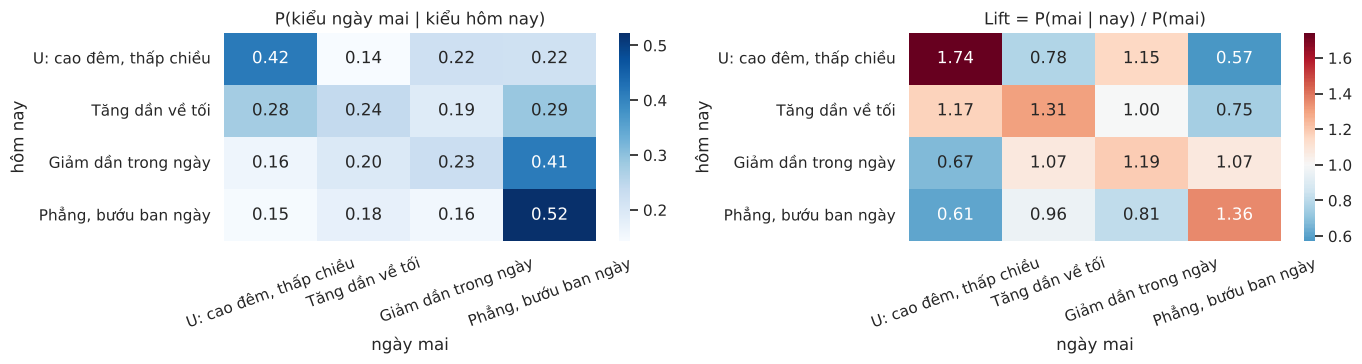

In [15]:
nxt = c["shape_cluster"].reindex(c.index + pd.Timedelta("1D"))
nxt.index = c.index
pair = pd.DataFrame({"hôm nay": c["shape_cluster"], "ngày mai": nxt}).dropna()
print("số cặp ngày liền nhau:", len(pair))
T = pd.crosstab(pair["hôm nay"], pair["ngày mai"], normalize="index")
base = pair["ngày mai"].value_counts(normalize=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
sns.heatmap(T, annot=True, fmt=".2f", cmap="Blues", ax=ax[0]); ax[0].set_title("P(kiểu ngày mai | kiểu hôm nay)")
sns.heatmap(T / base, annot=True, fmt=".2f", cmap="RdBu_r", center=1, ax=ax[1]); ax[1].set_title("Lift = P(mai | nay) / P(mai)")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(REPORT / "18b_transitions.png"); plt.show()

**Đọc:** lift > 1 nghĩa là cặp đó gặp nhiều hơn mức ngẫu nhiên. (Khái niệm lift sẽ dùng lại ở bước association rules.) Xem giá trị cụ thể trong hình; kết luận ở phần Tóm tắt.

### 9d. Ngày điển hình nhất của mỗi cụm

Ví dụ thực tế (ngày gần tâm cụm nhất) giúp kiểm tra tên cụm có hợp lý không, và để đối chiếu với tin tức sau này.

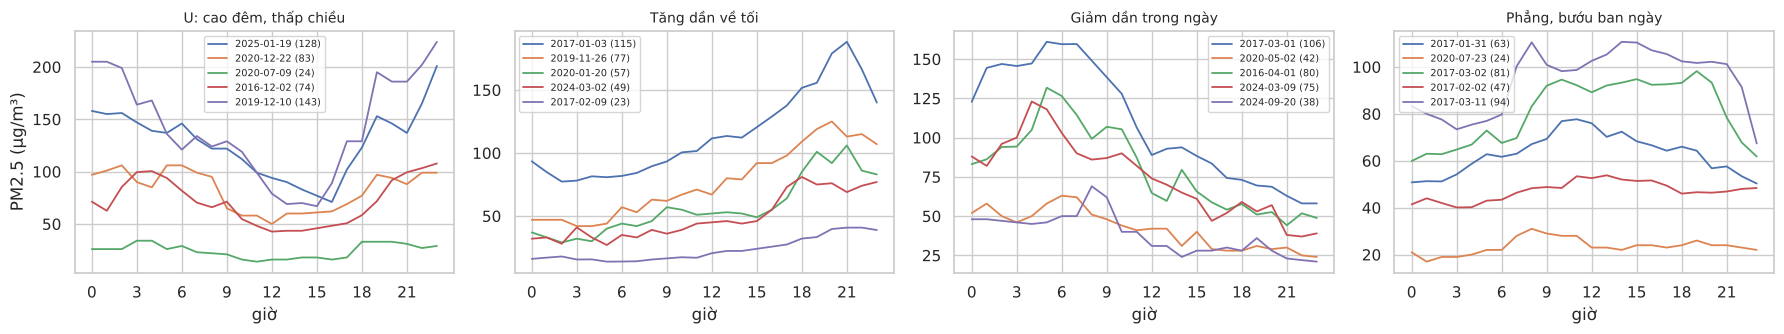

In [16]:
fig, ax = plt.subplots(1, K, figsize=(18, 3.5))
for a, n in zip(ax, ORDER):
    top = c[c["shape_cluster"] == n].nlargest(5, "shape_conf")
    for dt, r in top.iterrows():
        a.plot(range(24), r[HCOLS].values.astype(float), lw=1.3, label=f"{dt.date()} ({r['pm25_mean']:.0f})")
    a.set_title(n, fontsize=10); a.set_xticks(range(0, 24, 3)); a.legend(fontsize=7); a.set_xlabel("giờ")
ax[0].set_ylabel("PM2.5 (µg/m³)")
plt.tight_layout(); plt.savefig(REPORT / "19_examples.png"); plt.show()

## 10. So sánh nhanh với cách A (k-means trên log đường cong, giữ mức)

Để thấy vì sao tách 2 tầng: phân cụm trên log x (không trừ mức), k = 4, rồi xem cụm đó liên hệ với mùa và với bậc mức thế nào.

In [17]:
labA = KMeans(4, n_init=20, random_state=SEED).fit_predict(L.values)
cA = pd.Series(labA, index=c.index)
orderA = c.groupby(cA)["pm25_mean"].median().sort_values().index
display(pd.crosstab(cA, c["level_tier"]).loc[orderA])
display(pd.crosstab(cA, c["season"], normalize="index").loc[orderA].round(2))
print("ARI(cách A, bậc mức) =", round(adjusted_rand_score(cA, c["level_tier"].astype(str)), 2),
      "| ARI(cách A, cụm hình dạng) =", round(adjusted_rand_score(cA, c["shape_cluster"].astype(str)), 2))

level_tier,thấp,TB,cao
1,306,5,0
2,204,502,0
3,0,513,247
0,0,0,453


season,Đông,Xuân,Hè,Thu
1,0.12,0.05,0.69,0.14
2,0.14,0.14,0.56,0.16
3,0.30,0.24,0.28,0.19
0,0.53,0.11,0.07,0.29


ARI(cách A, bậc mức) = 0.39 | ARI(cách A, cụm hình dạng) = 0.03


**Đọc:** các cụm của cách A được sắp theo mức gần như tuyến tính (từ "sạch" tới "rất bẩn") và trùng phần lớn với bậc mức, gần như không liên quan tới cụm hình dạng. Tức là cách A chủ yếu tìm lại điều EDA đã biết ("mùa đông bẩn"), còn thông tin về nhịp trong ngày bị chìm. Đây là lý do chọn cách B.

## 11. Lưu nhãn cụm cho bước sau

In [18]:
cols = ["year", "month", "season", "pm25_mean", "gmean", "log_level", "shape_amp", "level_tier",
        "shape_cluster", "shape_code", "shape_conf", "day_type",
        "ws_mean", "ws_eve_minus_am", "precip_sum", "rain_0_12", "rain_12_24", "blh_mean", "blh_night", "t_range",
        "rh_mean", "wind_dir_mean", "viirs_n_rrd", "viirs_n_north", "viirs_n_rrd_lag1",
        "is_tet_holiday", "tet_day", "lockdown", "is_weekend", "dlog_prev", "dlog_next"]
lab = c[cols].copy()
lab["shape_cluster"] = lab["shape_cluster"].astype(str); lab["level_tier"] = lab["level_tier"].astype(str); lab["season"] = lab["season"].astype(str)
lab.to_parquet(OUT / "day_clusters.parquet"); lab.to_csv(OUT / "day_clusters.csv", float_format="%.4f")
pd.DataFrame(np.exp(km.cluster_centers_), index=[NAME[i] for i in range(K)], columns=[f"h{i:02d}" for i in range(24)]).loc[ORDER].round(4).to_csv(OUT / "shape_centroids.csv")
print(lab.shape, "->", OUT / "day_clusters.csv")
display(lab.head())

(2230, 31) -> data/day_clusters.csv


,year,month,season,pm25_mean,gmean,log_level,shape_amp,level_tier,shape_cluster,shape_code,...,wind_dir_mean,viirs_n_rrd,viirs_n_north,viirs_n_rrd_lag1,is_tet_holiday,tet_day,lockdown,is_weekend,dlog_prev,dlog_next
date,,,,,,,,,,,,,,,,,,,,,
2016-02-01,2016,2,Đông,24.377273,22.730241,3.123696,0.308365,thấp,Tăng dần về tối,S2_tang,...,18.358214,0.0,1.0,0.0,False,-7.0,False,False,NaN,0.645019
2016-02-02,2016,2,Đông,46.463636,43.605062,3.775173,0.274703,TB,Tăng dần về tối,S2_tang,...,26.661232,0.0,3.0,0.0,False,-6.0,False,False,0.645019,0.631773
2016-02-03,2016,2,Đông,87.395455,87.159256,4.467737,0.207971,cao,Tăng dần về tối,S2_tang,...,39.890482,0.0,0.0,0.0,False,-5.0,False,False,0.631773,-0.076920
2016-02-04,2016,2,Đông,80.925000,79.183588,4.371769,0.233348,cao,Giảm dần trong ngày,S3_giam,...,0.339345,0.0,3.0,0.0,False,-4.0,False,False,-0.076920,NaN
2016-02-09,2016,2,Đông,61.458333,58.540736,4.069723,0.307050,cao,"Phẳng, bướu ban ngày",S4_phang,...,139.409890,10.0,171.0,13.0,True,1.0,False,False,NaN,-0.171854


## 12. Tóm tắt, giới hạn, quyết định

**Phương pháp (mining):** k-means (k = 4) trên **hình dạng** `log PM2.5 − trung bình log của ngày` của 2.230 ngày; **mức** tách riêng thành 3 bậc (≤ 25, 25–50, > 50 µg/m³). Kiểu ngày = hình dạng × bậc mức (`day_type`).

**Kết quả chính (đều là mối liên hệ):**
1. Hình dạng ngày là **dải liên tục**, không có nhóm tách rời tự nhiên: silhouette ~0,14, không có khuỷu, các thuật toán khác (Ward, GMM, DTW) chỉ trùng một phần. k = 4 được chọn vì vẫn ổn định khi lấy mẫu lại (ARI 0,81; k = 2–3 nhỉnh hơn một chút, k ≥ 5 rơi xuống 0,5–0,7) và cả 4 tâm diễn giải được. Đọc cụm như **kiểu điển hình**.
2. Bốn hình dạng:
   - **U: cao đêm, thấp chiều** (24%): ngày khô, ít ẩm, biên độ nhiệt lớn, lớp biên đêm thấp; nhiều nhất tháng 10–11; thường kéo dài nhiều ngày liền (hôm nay U → mai U: 42%, lift 1,75); mức cao hơn bình thường của tháng ~15%.
   - **Tăng dần về tối** (18%): gió yếu đi về chiều tối; hôm nay còn tương đối sạch nhưng ngày mai thường bẩn hơn ~32%; hay được nối tiếp bằng U (lift 1,2). Dáng **đầu đợt ô nhiễm**.
   - **Giảm dần trong ngày** (19%): gió mạnh lên về chiều tối, ẩm hơn; hôm nay bẩn nhưng ngày mai thường sạch hơn ~21%; hay được nối tiếp bằng ngày Phẳng (41%). Dáng **cuối đợt ô nhiễm**.
   - **Phẳng, bướu ban ngày** (39%): điều kiện gần bình thường, nhịp ngày yếu; chiếm ưu thế tháng 2–5 (nồm ẩm) và kỳ nghỉ Tết.
3. **Mức** liên hệ với khả năng phát tán trong cùng mùa: bậc "cao" đi kèm gió yếu (~2 m/s), lớp biên thấp, không mưa, biên độ nhiệt lớn, nhiều điểm cháy hơn (rõ nhất mùa Thu). **Hình dạng** liên hệ với diễn biến thời tiết **trong ngày** (gió đổi giữa sáng và tối) và vị trí của ngày trong một đợt ô nhiễm.
4. Gợi ý một "vòng đời" đợt ô nhiễm: Tăng dần → U (một hoặc nhiều ngày) → Giảm dần → Phẳng. Đây là quan sát từ ma trận chuyển tiếp, xác suất chỉ ở mức 0,2–0,4; cần kiểm tra thêm.

**Giới hạn:**
- **Một trạm** (Ba Đình); hình dạng ngày ở ngoại thành hoặc gần khu công nghiệp có thể khác.
- Mẫu ngày lệch: 2019, 2021, 2022, 2023 thiếu nhiều tháng, 2025 chỉ đến 08/04; không so tỷ lệ cụm giữa các năm. 35 ngày có đường cong đủ nhờ nội suy đã bị loại; 579 ngày còn lại có 1–3 giờ nội suy.
- Ranh giới cụm phụ thuộc thuật toán (ARI giữa các thuật toán 0,24–0,47); kết luận nên dựa trên **lõi** cụm (`shape_conf` cao), không phải từng ngày lẻ.
- Thời tiết là tái phân tích ERA5 (~25 km), không đo tại trạm; BLH thiếu nửa đầu 2024. Điểm cháy FIRMS chỉ trong Việt Nam, bị mây che.
- Giả định lệch nhãn giờ −1h (Giai đoạn 1) chưa chắc chắn; nếu sai, mọi đường cong dịch 1 giờ, nhưng tên các cụm không đổi.
- Mốc bậc mức 25 µg/m³ là lựa chọn của dự án, không phải ngưỡng pháp lý.
- Tất cả là **mối liên hệ**; ví dụ "gió mạnh lên về tối" đi kèm "Giảm dần" không chứng minh gió là nguyên nhân duy nhất.

**Đầu vào cho bước association rules:** `data/day_clusters.csv` có `shape_code`, `level_tier`, `day_type`, `shape_conf` và các biến điều kiện (gió, gió tối − sáng, mưa sáng/chiều, BLH, biên độ nhiệt, độ ẩm, điểm cháy, Tết, giãn cách, mức hôm trước/hôm sau). Bước sau sẽ rời rạc hóa các biến này (theo phân vị trong từng tháng để khử mùa) và tìm luật dạng `{gió tối mạnh lên, ẩm cao} → S3_giam`.

**Quyết định nên ghi vào "Nhật ký quyết định":**
- Phân cụm trên hình dạng `log x − mean(log x)`, mức tách riêng thành 3 bậc ≤ 25 / 25–50 / > 50 µg/m³ (theo QCVN 50).
- k-means, k = 4, chọn theo độ ổn định bootstrap và khả năng diễn giải (không theo silhouette).
- Chỉ dùng ngày có đường cong 24h **và** ≥ 18 giờ đo thật (2.230 ngày, sau khi Giai đoạn 1 gắn cờ lỗi đo gần 0).
- Mô tả điều kiện bằng anomaly so với trung vị cùng tháng.